In [2]:
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

Setup Configuration

In [3]:
DATASET_PATH = Path(
    "/kaggle/input/datasets/angelinacandaya/fashion-mnist/fashion_mnist_splits.pt"
)

CONFIG_PATH = Path(
    "/kaggle/input/datasets/angelinacandaya/gan-model-config/config.json"
)

PROJECT_DIR = Path("/kaggle/working")
CHECKPOINTS_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r") as file:
    CONFIG = json.load(file)

GENERAL_CONFIG = CONFIG["general"]
DDPM_CONFIG = CONFIG["models"]["ddpm"]

random.seed(GENERAL_CONFIG["random_seed"])
np.random.seed(GENERAL_CONFIG["random_seed"])
torch.manual_seed(GENERAL_CONFIG["random_seed"])

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GENERAL_CONFIG["random_seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project:", GENERAL_CONFIG["project_name"])
print("Dataset:", GENERAL_CONFIG["dataset"])
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Timesteps:", DDPM_CONFIG["timesteps"])
print("Epochs:", DDPM_CONFIG["epochs"])
print("Batch Size:", GENERAL_CONFIG["batch_size"])
print("Dataset exists:", DATASET_PATH.exists())
print("Config exists:", CONFIG_PATH.exists())

Project: Generative Models Comparison
Dataset: Fashion-MNIST
Device: cuda
GPU: Tesla T4
Timesteps: 1000
Epochs: 50
Batch Size: 128
Dataset exists: True
Config exists: True


Load Dataset

In [4]:
dataset = torch.load(
    DATASET_PATH,
    map_location="cpu",
    weights_only=False
)

In [5]:
print("Dataset Keys:", dataset.keys())

for key, value in dataset.items():
    if isinstance(value, torch.Tensor):
        print(f"{key}: {value.shape}")
    else:
        print(f"{key}: {type(value)}")

Dataset Keys: dict_keys(['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels'])
train_images: torch.Size([56000, 1, 28, 28])
train_labels: torch.Size([56000])
val_images: torch.Size([7000, 1, 28, 28])
val_labels: torch.Size([7000])
test_images: torch.Size([7000, 1, 28, 28])
test_labels: torch.Size([7000])


In [6]:
X_train = dataset["train_images"]
y_train = dataset["train_labels"]

X_val = dataset["val_images"]
y_val = dataset["val_labels"]

X_test = dataset["test_images"]
y_test = dataset["test_labels"]

print("Training Images:", X_train.shape)
print("Validation Images:", X_val.shape)
print("Testing Images:", X_test.shape)

Training Images: torch.Size([56000, 1, 28, 28])
Validation Images: torch.Size([7000, 1, 28, 28])
Testing Images: torch.Size([7000, 1, 28, 28])


Normalize Images

In [7]:
X_train = X_train.float() / 127.5 - 1.0
X_val = X_val.float() / 127.5 - 1.0
X_test = X_test.float() / 127.5 - 1.0

print("Training Pixel Range:")
print("Minimum:", X_train.min().item())
print("Maximum:", X_train.max().item())

print("\nValidation Pixel Range:")
print("Minimum:", X_val.min().item())
print("Maximum:", X_val.max().item())

Training Pixel Range:
Minimum: -1.0
Maximum: 1.0

Validation Pixel Range:
Minimum: -1.0
Maximum: 1.0


DataLoader

In [8]:
train_dataset = TensorDataset(X_train)
val_dataset = TensorDataset(X_val)
test_dataset = TensorDataset(X_test)

BATCH_SIZE = GENERAL_CONFIG["batch_size"]

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Training Batches: 438
Validation Batches: 55
Testing Batches: 55


Diffusion Schedule

In [31]:
# Create diffusion schedule
TIMESTEPS = DDPM_CONFIG["timesteps"]
BETA_START = 0.0001
BETA_END = 0.02

betas = torch.linspace(
    BETA_START,
    BETA_END,
    TIMESTEPS,
    device=device
)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

# Calculate posterior variance
alpha_bars_previous = torch.cat([
    torch.ones(1, device=device),
    alpha_bars[:-1]
])

posterior_variance = (
    betas * (1.0 - alpha_bars_previous) / (1.0 - alpha_bars)
)

print("Beta Shape:", betas.shape)
print("Beta Range:", betas.min().item(), "-", betas.max().item())
print("Alpha Bar Min:", alpha_bars.min().item())
print("Alpha Bar Max:", alpha_bars.max().item())
print("Schedule Device:", betas.device)

Beta Shape: torch.Size([1000])
Beta Range: 9.999999747378752e-05 - 0.019999999552965164
Alpha Bar Min: 4.035829260828905e-05
Alpha Bar Max: 0.9998999834060669
Schedule Device: cuda:0


In [32]:
checkpoint_path = "/kaggle/working/checkpoints/ddpm.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

unet.load_state_dict(checkpoint["model_state_dict"])
unet = unet.to(device)

print("Previous DDPM Checkpoint Loaded")
print("Checkpoint Epoch:", checkpoint["epoch"])
print("Model Device:", next(unet.parameters()).device)


Previous DDPM Checkpoint Loaded
Checkpoint Epoch: 50
Model Device: cuda:0


In [33]:
LEARNING_RATE = 0.0001
FINE_TUNE_EPOCHS = 10

optimizer = torch.optim.Adam(
    unet.parameters(),
    lr=LEARNING_RATE
)

criterion = torch.nn.MSELoss()

print("Fine-Tuning Configuration")
print("Epochs:", FINE_TUNE_EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Optimizer: Adam")
print("Loss Function: MSE")


Fine-Tuning Configuration
Epochs: 10
Learning Rate: 0.0001
Optimizer: Adam
Loss Function: MSE


Forward Diffusion Function

In [10]:
def forward_diffusion(images, timesteps, noise=None):
    if noise is None:
        noise = torch.randn_like(images)

    sqrt_alpha_bar = sqrt_alpha_bars[timesteps].view(-1, 1, 1, 1)
    sqrt_one_minus_alpha_bar = sqrt_one_minus_alpha_bars[timesteps].view(-1, 1, 1, 1)

    noisy_images = (
        sqrt_alpha_bar * images
        + sqrt_one_minus_alpha_bar * noise
    )

    return noisy_images, noise

Test Forward Diffusion

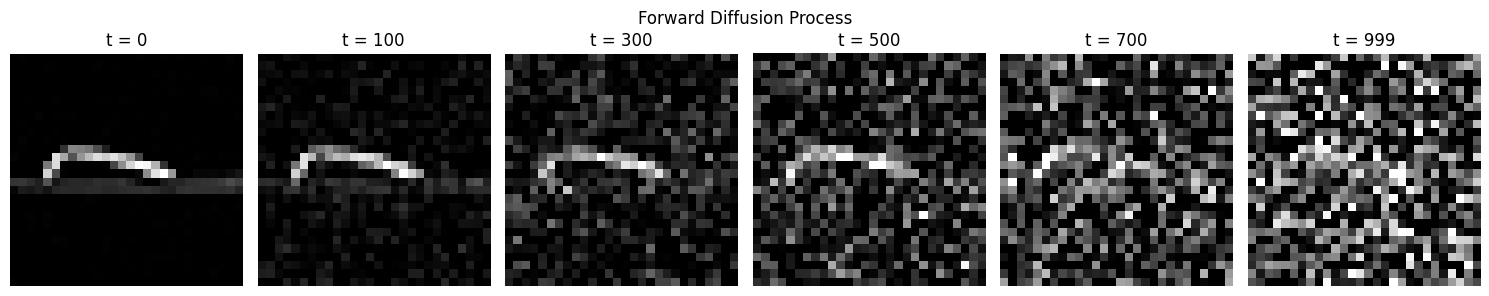

In [11]:
sample_image = X_train[0:1].to(device)

selected_timesteps = [0, 100, 300, 500, 700, 999]

fig, axes = plt.subplots(1, 6, figsize=(15, 3))

for ax, timestep in zip(axes, selected_timesteps):
    t = torch.tensor([timestep], device=device)

    noisy_image, _ = forward_diffusion(sample_image, t)

    ax.imshow(
        noisy_image.squeeze().cpu().numpy(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    ax.set_title(f"t = {timestep}")
    ax.axis("off")

plt.suptitle("Forward Diffusion Process")
plt.tight_layout()

plt.savefig(RESULTS_DIR / "ddpm_forward_diffusion.png", dpi=100)
plt.show()

Sinusoidal Time Embedding

In [12]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.embedding_dim = embedding_dim

    def forward(self, timesteps):
        half_dim = self.embedding_dim // 2

        embeddings = torch.log(
            torch.tensor(10000.0, device=timesteps.device)
        ) / (half_dim - 1)

        embeddings = torch.exp(
            torch.arange(half_dim, device=timesteps.device) * -embeddings
        )

        embeddings = timesteps.float().unsqueeze(1) * embeddings.unsqueeze(0)

        embeddings = torch.cat(
            [torch.sin(embeddings), torch.cos(embeddings)],
            dim=1
        )

        return embeddings

Residual Block

In [13]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_dim, out_channels)
        )

        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.GroupNorm(8, out_channels)
        )

        self.shortcut = (
            nn.Conv2d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )

        self.activation = nn.SiLU()

    def forward(self, x, time_embedding):
        residual = self.shortcut(x)

        x = self.conv1(x)

        time_features = self.time_mlp(time_embedding)
        x = x + time_features[:, :, None, None]

        x = self.conv2(x)

        return self.activation(x + residual)

Downsample dan Upsample Blocks

In [14]:
class DownsampleBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.conv = nn.Conv2d(
            channels,
            channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

    def forward(self, x):
        return self.conv(x)


class UpsampleBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

    def forward(self, x):
        return self.conv(x)

Build U-Net Architecture

In [15]:
class UNet(nn.Module):
    def __init__(self, config):
        super().__init__()

        channels = config["channels"]
        time_dim = channels[0] * 4

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(channels[0]),
            nn.Linear(channels[0], time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input_conv = nn.Conv2d(
            1, channels[0], kernel_size=3, padding=1
        )

        self.down1 = ResidualBlock(channels[0], channels[0], time_dim)
        self.downsample1 = DownsampleBlock(channels[0])

        self.down2 = ResidualBlock(channels[0], channels[1], time_dim)
        self.downsample2 = DownsampleBlock(channels[1])

        self.middle = ResidualBlock(channels[1], channels[2], time_dim)

        self.upsample1 = UpsampleBlock(channels[2], channels[1])
        self.up1 = ResidualBlock(channels[1] * 2, channels[1], time_dim)

        self.upsample2 = UpsampleBlock(channels[1], channels[0])
        self.up2 = ResidualBlock(channels[0] * 2, channels[0], time_dim)

        self.output = nn.Sequential(
            nn.Conv2d(channels[0], channels[0], kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(channels[0], 1, kernel_size=1)
        )

    def forward(self, x, timesteps):
        time_embedding = self.time_embedding(timesteps)

        x = self.input_conv(x)

        skip1 = self.down1(x, time_embedding)
        x = self.downsample1(skip1)

        skip2 = self.down2(x, time_embedding)
        x = self.downsample2(skip2)

        x = self.middle(x, time_embedding)

        x = self.upsample1(x)
        x = torch.cat([x, skip2], dim=1)
        x = self.up1(x, time_embedding)

        x = self.upsample2(x)
        x = torch.cat([x, skip1], dim=1)
        x = self.up2(x, time_embedding)

        return self.output(x)


unet = UNet(DDPM_CONFIG).to(device)

print(unet)

UNet(
  (time_embedding): Sequential(
    (0): SinusoidalTimeEmbedding()
    (1): Linear(in_features=64, out_features=256, bias=True)
    (2): SiLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
  (input_conv): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down1): ResidualBlock(
    (conv1): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (2): SiLU()
    )
    (time_mlp): Sequential(
      (0): SiLU()
      (1): Linear(in_features=256, out_features=64, bias=True)
    )
    (conv2): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): GroupNorm(8, 64, eps=1e-05, affine=True)
    )
    (shortcut): Identity()
    (activation): SiLU()
  )
  (downsample1): DownsampleBlock(
    (conv): Conv2d(64, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  )
  (down2): ResidualBlock(
    (conv1): Sequential(
 

Test U-Net Forward Pass

In [16]:
test_images = torch.randn(8, 1, 28, 28).to(device)
test_timesteps = torch.randint(0, TIMESTEPS, (8,)).to(device)

with torch.no_grad():
    predicted_noise = unet(test_images, test_timesteps)

print("Input Shape:", test_images.shape)
print("Timestep Shape:", test_timesteps.shape)
print("Predicted Noise Shape:", predicted_noise.shape)


Input Shape: torch.Size([8, 1, 28, 28])
Timestep Shape: torch.Size([8])
Predicted Noise Shape: torch.Size([8, 1, 28, 28])


Setup Training

In [17]:
criterion = nn.MSELoss()

learning_rate = DDPM_CONFIG["learning_rate"]

optimizer = optim.Adam(
    unet.parameters(),
    lr=learning_rate
)

EPOCHS = DDPM_CONFIG["epochs"]

train_losses = []
val_losses = []

checkpoint_path = CHECKPOINTS_DIR / "ddpm.pth"

print("Learning Rate:", learning_rate)
print("Epochs:", EPOCHS)
print("Loss Function:", criterion)
print("Checkpoint Path:", checkpoint_path)

Learning Rate: 0.0002
Epochs: 50
Loss Function: MSELoss()
Checkpoint Path: /kaggle/working/checkpoints/ddpm.pth


Train DDPM

In [18]:
for epoch in range(EPOCHS):
    unet.train()
    total_train_loss = 0

    for (images,) in train_loader:
        images = images.to(device)
        batch_size = images.size(0)

        # Sample random timesteps
        timesteps = torch.randint(
            0, TIMESTEPS, (batch_size,), device=device
        )

        # Add Gaussian noise
        noisy_images, noise = forward_diffusion(images, timesteps)

        # Predict noise
        predicted_noise = unet(noisy_images, timesteps)

        # Calculate loss
        loss = criterion(predicted_noise, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation
    unet.eval()
    total_val_loss = 0

    with torch.no_grad():
        for (images,) in val_loader:
            images = images.to(device)
            batch_size = images.size(0)

            timesteps = torch.randint(
                0, TIMESTEPS, (batch_size,), device=device
            )

            noisy_images, noise = forward_diffusion(images, timesteps)
            predicted_noise = unet(noisy_images, timesteps)

            val_loss = criterion(predicted_noise, noise)
            total_val_loss += val_loss.item()

    avg_val_loss = total_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    # Save checkpoint every 10 epochs
    if (epoch + 1) % 10 == 0:
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": unet.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_losses": train_losses,
            "val_losses": val_losses
        }, checkpoint_path)

        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] "
            f"Train Loss: {avg_train_loss:.6f} "
            f"Val Loss: {avg_val_loss:.6f}"
        )

Epoch [10/50] Train Loss: 0.094678 Val Loss: 0.096255
Epoch [20/50] Train Loss: 0.090996 Val Loss: 0.091421
Epoch [30/50] Train Loss: 0.088205 Val Loss: 0.088484
Epoch [40/50] Train Loss: 0.087595 Val Loss: 0.086424
Epoch [50/50] Train Loss: 0.086170 Val Loss: 0.088119


In [20]:
# Display training and validation loss for each epoch
for epoch, (train_loss, val_loss) in enumerate(
    zip(train_losses, val_losses), start=1
):
    print(
        f"Epoch [{epoch}/50] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )

Epoch [1/50] Train Loss: 0.169212 Val Loss: 0.120963
Epoch [2/50] Train Loss: 0.115968 Val Loss: 0.109106
Epoch [3/50] Train Loss: 0.108031 Val Loss: 0.105951
Epoch [4/50] Train Loss: 0.103631 Val Loss: 0.105300
Epoch [5/50] Train Loss: 0.100802 Val Loss: 0.099674
Epoch [6/50] Train Loss: 0.099400 Val Loss: 0.099351
Epoch [7/50] Train Loss: 0.097770 Val Loss: 0.097291
Epoch [8/50] Train Loss: 0.096682 Val Loss: 0.096753
Epoch [9/50] Train Loss: 0.096774 Val Loss: 0.094946
Epoch [10/50] Train Loss: 0.094678 Val Loss: 0.096255
Epoch [11/50] Train Loss: 0.094679 Val Loss: 0.094450
Epoch [12/50] Train Loss: 0.093605 Val Loss: 0.093507
Epoch [13/50] Train Loss: 0.092598 Val Loss: 0.092629
Epoch [14/50] Train Loss: 0.092726 Val Loss: 0.091455
Epoch [15/50] Train Loss: 0.092174 Val Loss: 0.093743
Epoch [16/50] Train Loss: 0.091762 Val Loss: 0.090174
Epoch [17/50] Train Loss: 0.091142 Val Loss: 0.092660
Epoch [18/50] Train Loss: 0.090939 Val Loss: 0.090605
Epoch [19/50] Train Loss: 0.091484 Va

Load trained model

In [26]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

unet.load_state_dict(checkpoint["model_state_dict"])
unet.to(device)
unet.eval()

print("DDPM Model Loaded Successfully")
print("Checkpoint Epoch:", checkpoint["epoch"])
print("Model Device:", next(unet.parameters()).device)

DDPM Model Loaded Successfully
Checkpoint Epoch: 50
Model Device: cuda:0


Define Reverse Diffusion

In [27]:
@torch.no_grad()
def reverse_diffusion(model, num_samples=10):
    model.eval()

    images = torch.randn(
        num_samples, 1, 28, 28, device=device
    )

    for t in reversed(range(TIMESTEPS)):
        timesteps = torch.full(
            (num_samples,), t,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(images, timesteps)

        beta_t = betas[t]
        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]

        mean = (1 / torch.sqrt(alpha_t)) * (
            images -
            (beta_t / torch.sqrt(1 - alpha_bar_t)) * predicted_noise
        )

        if t > 0:
            noise = torch.randn_like(images)
            images = mean + torch.sqrt(posterior_variance[t]) * noise
        else:
            images = mean

    return images.clamp(-1, 1)

Generate Images

In [28]:
generated_images = reverse_diffusion(
    unet,
    num_samples=10
)

print("Generated Images Shape:", generated_images.shape)
print("Pixel Minimum:", generated_images.min().item())
print("Pixel Maximum:", generated_images.max().item())

Generated Images Shape: torch.Size([10, 1, 28, 28])
Pixel Minimum: -1.0
Pixel Maximum: 1.0


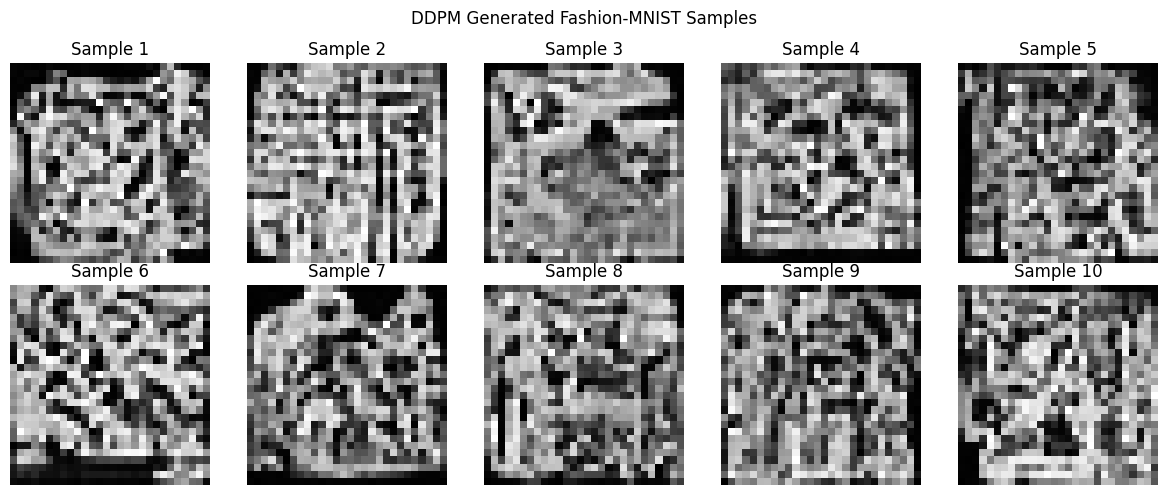

In [29]:
generated_images_display = (generated_images.detach().cpu() + 1) / 2

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images_display[i, 0], cmap="gray")
    ax.axis("off")
    ax.set_title(f"Sample {i+1}")

plt.suptitle("DDPM Generated Fashion-MNIST Samples")
plt.tight_layout()

plt.savefig(RESULTS_DIR / "ddpm_generated_samples.png", dpi=300)
plt.show()

In [30]:
test_betas = torch.linspace(
    0.0001,
    0.02,
    1000,
    device=device
)

test_alphas = 1.0 - test_betas
test_alpha_bars = torch.cumprod(test_alphas, dim=0)

print("New Alpha Bar Min:", test_alpha_bars.min().item())
print("New Alpha Bar Max:", test_alpha_bars.max().item())

New Alpha Bar Min: 4.035829260828905e-05
New Alpha Bar Max: 0.9998999834060669


# Fine-Tuning Training


In [34]:
fine_tune_train_losses = []
fine_tune_val_losses = []

fine_tune_checkpoint_path = (
    "/kaggle/working/checkpoints/ddpm_finetuned.pth"
)

for epoch in range(FINE_TUNE_EPOCHS):
    unet.train()
    total_train_loss = 0

    # Training
    for (images,) in train_loader:
        images = images.to(device)
        batch_size = images.size(0)

        timesteps = torch.randint(
            0, TIMESTEPS, (batch_size,), device=device
        )

        noisy_images, noise = forward_diffusion(images, timesteps)
        predicted_noise = unet(noisy_images, timesteps)

        loss = criterion(predicted_noise, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)
    fine_tune_train_losses.append(avg_train_loss)

    # Validation
    unet.eval()
    total_val_loss = 0

    with torch.no_grad():
        for (images,) in val_loader:
            images = images.to(device)
            batch_size = images.size(0)

            timesteps = torch.randint(
                0, TIMESTEPS, (batch_size,), device=device
            )

            noisy_images, noise = forward_diffusion(images, timesteps)
            predicted_noise = unet(noisy_images, timesteps)

            val_loss = criterion(predicted_noise, noise)
            total_val_loss += val_loss.item()

    avg_val_loss = total_val_loss / len(val_loader)
    fine_tune_val_losses.append(avg_val_loss)

    print(
        f"Fine-Tuning Epoch [{epoch + 1}/{FINE_TUNE_EPOCHS}] "
        f"Train Loss: {avg_train_loss:.6f} "
        f"Val Loss: {avg_val_loss:.6f}"
    )

# Save fine-tuned checkpoint
torch.save({
    "epoch": FINE_TUNE_EPOCHS,
    "model_state_dict": unet.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "train_losses": fine_tune_train_losses,
    "val_losses": fine_tune_val_losses,
    "beta_start": BETA_START,
    "beta_end": BETA_END,
    "timesteps": TIMESTEPS
}, fine_tune_checkpoint_path)

print("\nFine-Tuning Completed")
print("Checkpoint Saved:", fine_tune_checkpoint_path)
print("Final Train Loss:", fine_tune_train_losses[-1])
print("Final Val Loss:", fine_tune_val_losses[-1])


Fine-Tuning Epoch [1/10] Train Loss: 0.037240 Val Loss: 0.034932
Fine-Tuning Epoch [2/10] Train Loss: 0.034549 Val Loss: 0.034267
Fine-Tuning Epoch [3/10] Train Loss: 0.034433 Val Loss: 0.034191
Fine-Tuning Epoch [4/10] Train Loss: 0.034406 Val Loss: 0.034845
Fine-Tuning Epoch [5/10] Train Loss: 0.034027 Val Loss: 0.035787
Fine-Tuning Epoch [6/10] Train Loss: 0.034437 Val Loss: 0.036291
Fine-Tuning Epoch [7/10] Train Loss: 0.034613 Val Loss: 0.034532
Fine-Tuning Epoch [8/10] Train Loss: 0.033977 Val Loss: 0.033573
Fine-Tuning Epoch [9/10] Train Loss: 0.033979 Val Loss: 0.036073
Fine-Tuning Epoch [10/10] Train Loss: 0.034400 Val Loss: 0.036421

Fine-Tuning Completed
Checkpoint Saved: /kaggle/working/checkpoints/ddpm_finetuned.pth
Final Train Loss: 0.03440044571105476
Final Val Loss: 0.036420574581081215


In [35]:
checkpoint = torch.load(
    fine_tune_checkpoint_path,
    map_location=device,
    weights_only=False
)

unet.load_state_dict(checkpoint["model_state_dict"])
unet.eval()

print("Fine-Tuned DDPM Loaded")
print("Checkpoint Epoch:", checkpoint["epoch"])
print("Beta Start:", checkpoint["beta_start"])
print("Beta End:", checkpoint["beta_end"])


Fine-Tuned DDPM Loaded
Checkpoint Epoch: 10
Beta Start: 0.0001
Beta End: 0.02


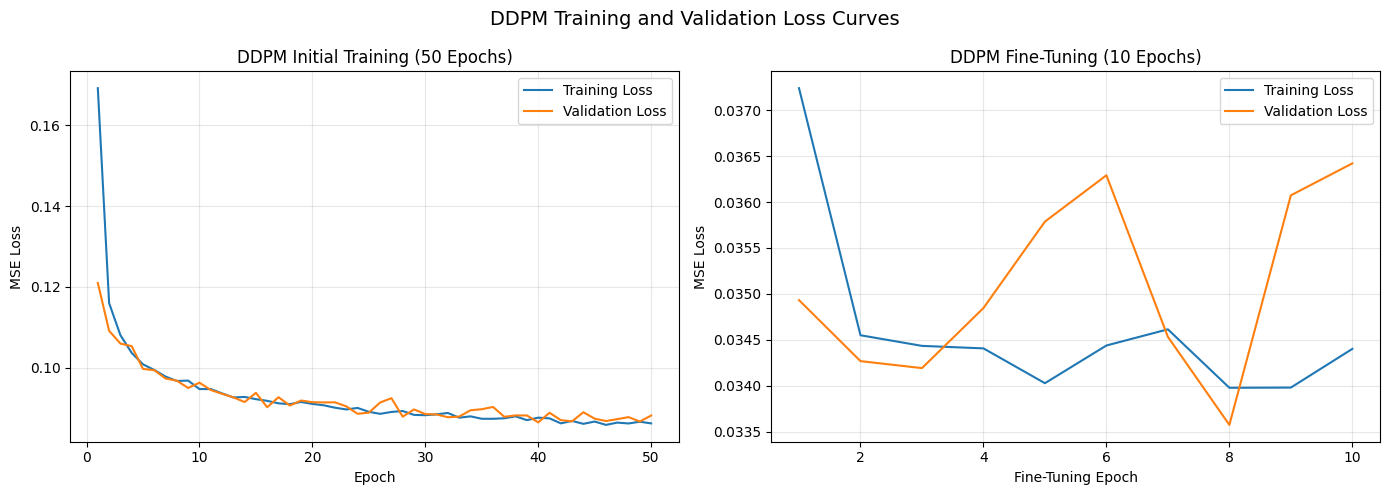

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    range(1, len(train_losses) + 1),
    train_losses,
    label="Training Loss"
)

axes[0].plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Validation Loss"
)

axes[0].set_title("DDPM Initial Training (50 Epochs)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    range(1, len(fine_tune_train_losses) + 1),
    fine_tune_train_losses,
    label="Training Loss"
)

axes[1].plot(
    range(1, len(fine_tune_val_losses) + 1),
    fine_tune_val_losses,
    label="Validation Loss"
)

axes[1].set_title("DDPM Fine-Tuning (10 Epochs)")
axes[1].set_xlabel("Fine-Tuning Epoch")
axes[1].set_ylabel("MSE Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("DDPM Training and Validation Loss Curves", fontsize=14)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ddpm_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [36]:
generated_images = reverse_diffusion(
    unet,
    num_samples=10
)

print("Generated Images Shape:", generated_images.shape)
print("Pixel Minimum:", generated_images.min().item())
print("Pixel Maximum:", generated_images.max().item())

Generated Images Shape: torch.Size([10, 1, 28, 28])
Pixel Minimum: -1.0
Pixel Maximum: 1.0


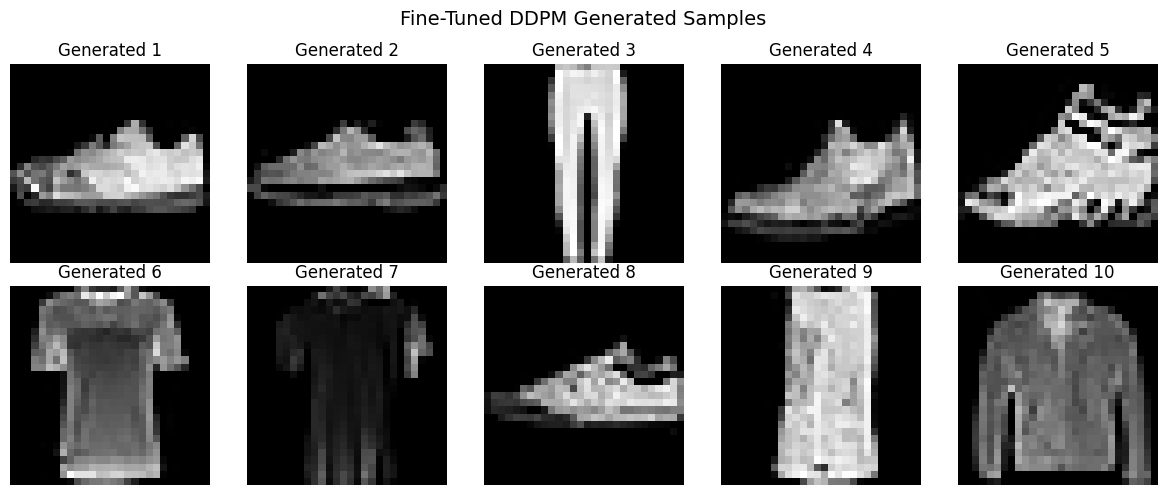

In [37]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = generated_images[i].squeeze().cpu().numpy()

    image = (image + 1) / 2

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Generated {i + 1}")
    ax.axis("off")

plt.suptitle("Fine-Tuned DDPM Generated Samples", fontsize=14)
plt.tight_layout()
plt.show()


In [43]:
unet.eval()

total_test_loss = 0

with torch.no_grad():
    for (images,) in test_loader:
        images = images.to(device)
        batch_size = images.size(0)

        timesteps = torch.randint(
            0,
            TIMESTEPS,
            (batch_size,),
            device=device
        )

        noisy_images, noise = forward_diffusion(images, timesteps)
        predicted_noise = unet(noisy_images, timesteps)

        test_loss = criterion(predicted_noise, noise)
        total_test_loss += test_loss.item()

avg_test_loss = total_test_loss / len(test_loader)

print("DDPM Test Evaluation")
print(f"Test Noise Prediction MSE: {avg_test_loss:.6f}")


DDPM Test Evaluation
Test Noise Prediction MSE: 0.035343
